# K10 Voice Snake - trening modelu keyword spotting

Model rozpoznaje słowa **up / down / left / right** (+ klasy `_silence_` i `_unknown_`) na podstawie zbioru **Google Speech Commands v2**.

Kroki:
1. Podłączenie Dysku Google (tam trafią wyniki).
2. Pobranie Speech Commands v2 (~2,3 GB, kilka minut).
3. Ekstrakcja cech log-mel **identycznych jak w `audio_features.h`** na K10.
4. Trening małego CNN, ocena, konwersja do **TFLite int8**.
5. Zapis na Dysk: `model_data.h` (do skopiowania obok `.ino`), `model_int8.tflite`, `model.keras`, wykresy.

Środowisko: wystarczy CPU, GPU (Runtime → Change runtime type → T4) przyspiesza trening.

In [1]:
# === Konfiguracja ===
WORDS  = ["up", "down", "left", "right"]
LABELS = ["_silence_", "_unknown_"] + WORDS

# Parametry cech - MUSZĄ być takie same jak w audio_features.h
SAMPLE_RATE = 16000
CLIP        = 16000
FRAME_LEN   = 480
FRAME_HOP   = 320
FFT_SIZE    = 512
N_MELS      = 40
FMIN        = 60.0
FMAX        = 7600.0
LOG_EPS     = 1e-6

UNKNOWN_RATIO = 1.0   # ile próbek _unknown_ względem średniej liczby próbek na słowo
SILENCE_RATIO = 1.0   # j.w. dla _silence_
AUG_COPIES    = 1     # dodatkowe zaugmentowane kopie każdej próbki treningowej
EPOCHS        = 30
BATCH         = 128
SEED          = 42

DATA_DIR  = "/content/speech_commands"
DRIVE_DIR = "/content/drive/MyDrive/k10_voice_snake"

In [2]:
# === Dysk Google ===
import os
from google.colab import drive
drive.mount("/content/drive")
os.makedirs(DRIVE_DIR, exist_ok=True)
print("Wyniki będą zapisane w:", DRIVE_DIR)

Mounted at /content/drive
Wyniki będą zapisane w: /content/drive/MyDrive/k10_voice_snake


In [3]:
# === Pobranie Speech Commands v2 ===
import os, subprocess
URL = "http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz"
if not os.path.exists(os.path.join(DATA_DIR, "up")):
    os.makedirs(DATA_DIR, exist_ok=True)
    subprocess.run(["wget", "-q", "--show-progress", "-O", "/content/sc.tar.gz", URL], check=True)
    subprocess.run(["tar", "-xzf", "/content/sc.tar.gz", "-C", DATA_DIR], check=True)
    os.remove("/content/sc.tar.gz")
print(sorted(os.listdir(DATA_DIR))[:12], "...")

['.DS_Store', 'LICENSE', 'README.md', '_background_noise_', 'backward', 'bed', 'bird', 'cat', 'dog', 'down', 'eight', 'five'] ...


In [4]:
# === Ekstrakcja cech (lustrzane odbicie audio_features.h) ===
import numpy as np

N_FRAMES = 1 + (CLIP - FRAME_LEN) // FRAME_HOP   # 49
N_BINS   = FFT_SIZE // 2 + 1                     # 257

def hz_to_mel(f): return 2595.0 * np.log10(1.0 + f / 700.0)
def mel_to_hz(m): return 700.0 * (10.0 ** (m / 2595.0) - 1.0)

def build_mel_fb():
    hz = mel_to_hz(np.linspace(hz_to_mel(FMIN), hz_to_mel(FMAX), N_MELS + 2))
    fk = np.arange(N_BINS) * SAMPLE_RATE / FFT_SIZE
    fb = np.zeros((N_MELS, N_BINS), dtype=np.float32)
    for m in range(N_MELS):
        l, c, r = hz[m], hz[m + 1], hz[m + 2]
        up = (fk - l) / (c - l)
        down = (r - fk) / (r - c)
        fb[m] = np.maximum(0.0, np.minimum(up, down))
    return fb

MEL_FB = build_mel_fb()
WINDOW = (0.5 - 0.5 * np.cos(2 * np.pi * np.arange(FRAME_LEN) / (FRAME_LEN - 1))).astype(np.float32)

def features(x):
    # x: float32, CLIP próbek, zakres [-1, 1] (czyli int16 / 32768)
    x = x.astype(np.float32)
    x = x - x.mean()
    idx = np.arange(N_FRAMES)[:, None] * FRAME_HOP + np.arange(FRAME_LEN)[None, :]
    frames = x[idx] * WINDOW
    spec = np.fft.rfft(frames, n=FFT_SIZE)
    power = (spec.real ** 2 + spec.imag ** 2).astype(np.float32)
    mel = power @ MEL_FB.T
    return np.log(mel + LOG_EPS).astype(np.float32)   # (49, 40)

print("Kształt cech:", features(np.zeros(CLIP, np.float32)).shape)

Kształt cech: (49, 40)


In [5]:
# === Lista plików i podział train / val / test (oficjalny podział zbioru) ===
import glob, random
from scipy.io import wavfile

rng = np.random.default_rng(SEED)
random.seed(SEED)

def read_list(name):
    with open(os.path.join(DATA_DIR, name)) as f:
        return set(line.strip() for line in f if line.strip())

val_set, test_set = read_list("validation_list.txt"), read_list("testing_list.txt")
split_files = {"train": {}, "val": {}, "test": {}}
for path in glob.glob(os.path.join(DATA_DIR, "*", "*.wav")):
    word = os.path.basename(os.path.dirname(path))
    if word.startswith("_"):
        continue
    rel = f"{word}/{os.path.basename(path)}"
    split = "val" if rel in val_set else "test" if rel in test_set else "train"
    split_files[split].setdefault(word, []).append(path)

for s in split_files:
    print(s, {w: len(split_files[s].get(w, [])) for w in WORDS})

def load_wav(path):
    sr, x = wavfile.read(path)
    assert sr == SAMPLE_RATE, (path, sr)
    x = x.astype(np.float32) / 32768.0
    if len(x) < CLIP:
        x = np.pad(x, (0, CLIP - len(x)))
    return x[:CLIP]

# Szum tła: 80% każdego pliku do treningu, 20% do walidacji/testu
noise_train, noise_eval = [], []
for p in glob.glob(os.path.join(DATA_DIR, "_background_noise_", "*.wav")):
    sr, x = wavfile.read(p)
    x = x.astype(np.float32) / 32768.0
    cut = int(len(x) * 0.8)
    noise_train.append(x[:cut]); noise_eval.append(x[cut:])
print("Plików szumu:", len(noise_train))

train {'up': 2948, 'down': 3134, 'left': 3037, 'right': 3019}
val {'up': 350, 'down': 377, 'left': 352, 'right': 363}
test {'up': 425, 'down': 406, 'left': 412, 'right': 396}
Plików szumu: 6


/tmp/ipykernel_429/1038504970.py:36: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sr, x = wavfile.read(p)


In [6]:
# === Augmentacja i budowa zbiorów ===
from tqdm.auto import tqdm

def noise_crop(pool):
    n = pool[rng.integers(len(pool))]
    s = rng.integers(0, len(n) - CLIP)
    return n[s:s + CLIP]

def augment(x, pool):
    shift = int(rng.integers(-1600, 1601))          # przesunięcie w czasie ±100 ms
    x = np.roll(x, shift)
    if shift > 0: x[:shift] = 0
    elif shift < 0: x[shift:] = 0
    x = x * 10 ** (rng.uniform(-12, 6) / 20)         # wzmocnienie 0.25x-2x (inny mikrofon niż w zbiorze)
    if rng.random() < 0.8:
        x = x + noise_crop(pool) * rng.uniform(0.0, 0.1)
    return np.clip(x, -1, 1)

def make_silence(pool):
    if rng.random() < 0.1:
        return np.zeros(CLIP, np.float32)
    return np.clip(noise_crop(pool) * rng.uniform(0.0, 1.0), -1, 1)

def build_split(split):
    files = split_files[split]
    pool = noise_train if split == "train" else noise_eval
    items = []  # (ścieżka lub None dla ciszy, etykieta)
    for w in WORDS:
        items += [(p, LABELS.index(w)) for p in files.get(w, [])]
    per_word = int(np.mean([len(files.get(w, [])) for w in WORDS]))
    others = [p for w, ps in files.items() if w not in WORDS for p in ps]
    unk = rng.choice(others, size=int(per_word * UNKNOWN_RATIO), replace=False)
    items += [(p, LABELS.index("_unknown_")) for p in unk]
    items += [(None, LABELS.index("_silence_"))] * int(per_word * SILENCE_RATIO)

    X, y = [], []
    copies = 1 + (AUG_COPIES if split == "train" else 0)
    for path, label in tqdm(items, desc=split):
        base = load_wav(path) if path is not None else None
        for c in range(copies):
            if base is None:
                x = make_silence(pool)
            elif c == 0:
                x = base
            else:
                x = augment(base.copy(), pool)
            X.append(features(x)); y.append(label)
    return np.stack(X)[..., None], np.array(y, np.int32)

X_train, y_train = build_split("train")
X_val,   y_val   = build_split("val")
X_test,  y_test  = build_split("test")
print(X_train.shape, X_val.shape, X_test.shape)
print("Rozkład klas (train):", np.bincount(y_train, minlength=len(LABELS)))

train:   0%|          | 0/18206 [00:00<?, ?it/s]

val:   0%|          | 0/2162 [00:00<?, ?it/s]

test:   0%|          | 0/2457 [00:00<?, ?it/s]

(36412, 49, 40, 1) (2162, 49, 40, 1) (2457, 49, 40, 1)
Rozkład klas (train): [6068 6068 5896 6268 6074 6038]


In [7]:
# === Normalizacja (stałe trafiają do model_data.h) ===
FEATURE_MEAN = float(X_train.mean())
FEATURE_STD  = float(X_train.std())
print("MEAN =", FEATURE_MEAN, " STD =", FEATURE_STD)
norm = lambda X: ((X - FEATURE_MEAN) / FEATURE_STD).astype(np.float32)
Xn_train, Xn_val, Xn_test = norm(X_train), norm(X_val), norm(X_test)

MEAN = -5.121972560882568  STD = 4.802601337432861


In [8]:
# === Model i trening ===
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.random.set_seed(SEED)

def build_model():
    inp = keras.Input(shape=(N_FRAMES, N_MELS, 1))
    x = layers.Conv2D(8, 3, padding="same", activation="relu")(inp)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(16, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    out = layers.Dense(len(LABELS), activation="softmax")(x)
    return keras.Model(inp, out)

model = build_model()
model.summary()
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(
    Xn_train, y_train, validation_data=(Xn_val, y_val),
    epochs=EPOCHS, batch_size=BATCH, shuffle=True,
    callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
               keras.callbacks.ReduceLROnPlateau(patience=3, factor=0.5)])

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 49, 40, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 49, 40, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 20, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 20, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 10, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 10, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        61,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,782 (264.77 KB)

 Trainable params: 67,782 (264.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
285/285 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.6294 - loss: 0.9755 - val_accuracy: 0.8247 - val_loss: 0.4665 - learning_rate: 0.0010
Epoch 2/30
285/285 ━━━━━━━━━━━━━━━━━━━━ 20s 5ms/step - accuracy: 0.8274 - loss: 0.4861 - val_accuracy: 0.8765 - val_loss: 0.3468 - learning_rate: 0.0010
Epoch 3/30
285/285 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8675 - loss: 0.3703 - val_accuracy: 0.8978 - val_loss: 0.3030 - learning_rate: 0.0010
Epoch 4/30
285/285 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8888 - loss: 0.3091 - val_accuracy: 0.9006 - val_loss: 0.2929 - learning_rate: 0.0010
Epoch 5/30
285/285 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9017 - loss: 0.2763 - val_accuracy: 0.9066 - val_loss: 0.2911 - learning_rate: 0.0010
Epoch 6/30
285/285 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9106 - loss: 0.2517 - val_accuracy: 0.9140 - val_loss: 0.2628 - learning_rate: 0.0010
Epoch 7/30
285/285 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9185 - loss: 0.2278

Dokładność na teście (float32): 0.9158
              precision    recall  f1-score   support

   _silence_      0.992     0.861     0.921       409
   _unknown_      0.850     0.844     0.847       409
          up      0.848     0.944     0.893       425
        down      0.925     0.916     0.921       406
        left      0.950     0.968     0.959       412
       right      0.950     0.962     0.956       396

    accuracy                          0.916      2457
   macro avg      0.919     0.916     0.916      2457
weighted avg      0.918     0.916     0.916      2457



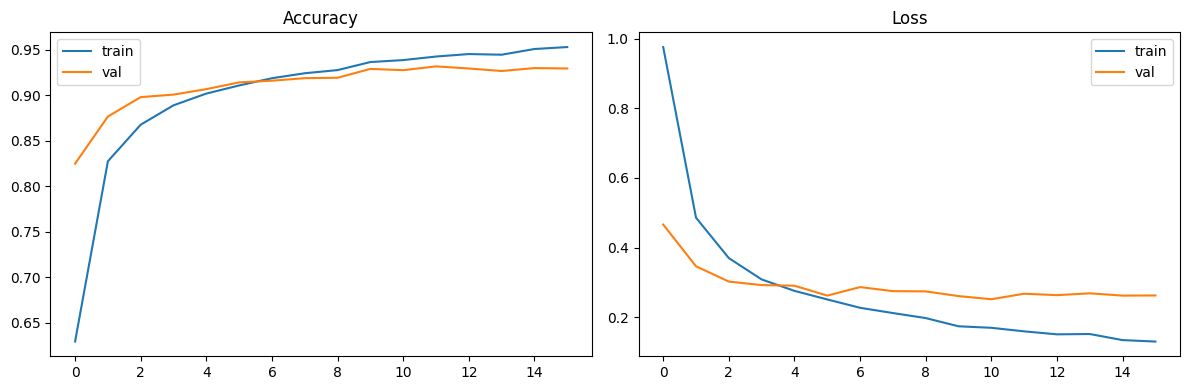

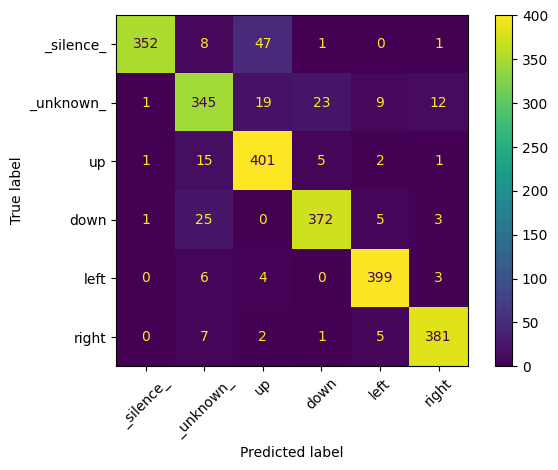

In [9]:
# === Ocena modelu float32 ===
import os
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

test_loss, test_acc = model.evaluate(Xn_test, y_test, verbose=0)
print(f"Dokładność na teście (float32): {test_acc:.4f}")
pred = model.predict(Xn_test, verbose=0).argmax(1)
print(classification_report(y_test, pred, target_names=LABELS, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train"); ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train"); ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(DRIVE_DIR, "training_history.png"), dpi=120); plt.show()

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=LABELS).plot(xticks_rotation=45)
plt.tight_layout(); plt.savefig(os.path.join(DRIVE_DIR, "confusion_matrix.png"), dpi=120); plt.show()

In [10]:
# === Konwersja do TFLite int8 ===
import shutil
SAVED = "/content/saved_model_kws"
shutil.rmtree(SAVED, ignore_errors=True)
# Wersja do eksportu: batch=1, a warstwy Flatten+Dense zamienione na równoważne Conv2D.
# Graf na K10 zawiera wtedy tylko CONV_2D, MAX_POOL_2D i SOFTMAX (bez RESHAPE/SHAPE/PACK).
def make_export_model(m):
    pools = [i for i, l in enumerate(m.layers) if isinstance(l, layers.MaxPooling2D)]
    last_pool = pools[-1]
    fh, fw, fc = m.layers[last_pool].output.shape[1:]
    d1, d2 = [l for l in m.layers if isinstance(l, layers.Dense)]
    inp = keras.Input(shape=(N_FRAMES, N_MELS, 1), batch_size=1)
    x = inp
    for l in m.layers[1:last_pool + 1]:
        x = l(x)
    c1 = layers.Conv2D(d1.units, (fh, fw), activation="relu"); x = c1(x)
    c2 = layers.Conv2D(d2.units, 1); x = c2(x)
    out = layers.Softmax()(x)
    em = keras.Model(inp, out)
    w, b = d1.get_weights(); c1.set_weights([w.reshape(fh, fw, fc, d1.units), b])
    w, b = d2.get_weights(); c2.set_weights([w.reshape(1, 1, d1.units, d2.units), b])
    return em

export_model = make_export_model(model)
diff = np.abs(model.predict(Xn_test[:8], verbose=0) -
              np.concatenate([export_model.predict(Xn_test[i:i + 1], verbose=0).reshape(1, -1) for i in range(8)])).max()
print("Różnica model vs model eksportowy:", diff)
try:
    export_model.export(SAVED)                 # Keras 3
except AttributeError:
    tf.saved_model.save(export_model, SAVED)   # starszy Keras

def representative_dataset():
    idx = rng.choice(len(Xn_train), size=500, replace=False)
    for i in idx:
        yield [Xn_train[i:i + 1]]

conv = tf.lite.TFLiteConverter.from_saved_model(SAVED)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = representative_dataset
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8
conv.inference_output_type = tf.int8
tflite_model = conv.convert()
print(f"Rozmiar modelu int8: {len(tflite_model) / 1024:.1f} KB")

# Sprawdzenie dokładności modelu int8 (tak jak policzy go K10)
interp = tf.lite.Interpreter(model_content=tflite_model)
interp.allocate_tensors()
inp_d, out_d = interp.get_input_details()[0], interp.get_output_details()[0]
in_scale, in_zp = inp_d["quantization"]
ok = 0
for i in range(len(Xn_test)):
    q = np.clip(np.round(Xn_test[i:i + 1] / in_scale + in_zp), -128, 127).astype(np.int8)
    interp.set_tensor(inp_d["index"], q)
    interp.invoke()
    ok += int(interp.get_tensor(out_d["index"])[0].argmax() == y_test[i])
print(f"Dokładność na teście (int8): {ok / len(Xn_test):.4f}")
try:
    print("Operacje w modelu:", sorted({o["op_name"] for o in interp._get_ops_details()}))
except Exception:
    pass

Różnica model vs model eksportowy: 2.7939677e-08
Saved artifact at '/content/saved_model_kws'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 49, 40, 1), dtype=tf.float32, name='keras_tensor_11')
Output Type:
  TensorSpec(shape=(None, 1, 1, 6), dtype=tf.float32, name=None)
Captures:
  137747665073744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137747665074704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137747665074320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137747665075088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137747665074128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137747665075856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137747187621840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137747187617808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137747187616080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137747187625872: Ten

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Dokładność na teście (int8): 0.9186
Operacje w modelu: ['CONV_2D', 'DELEGATE', 'MAX_POOL_2D', 'SOFTMAX']


In [11]:
# === Zapis na Dysk Google: model_data.h, .tflite, .keras ===
def write_header(path, data):
    lines = [
        "// Wygenerowane automatycznie przez notebook train_kws_k10.ipynb - nie edytuj ręcznie.",
        "#pragma once",
        "#include <stdint.h>",
        "",
        f"#define MODEL_FEAT_SAMPLE_RATE {SAMPLE_RATE}",
        f"#define MODEL_FEAT_CLIP_SAMPLES {CLIP}",
        f"#define MODEL_FEAT_FRAME_LEN {FRAME_LEN}",
        f"#define MODEL_FEAT_FRAME_HOP {FRAME_HOP}",
        f"#define MODEL_FEAT_FFT_SIZE {FFT_SIZE}",
        f"#define MODEL_FEAT_NUM_MELS {N_MELS}",
        f"#define MODEL_FEAT_FMIN {FMIN:.1f}f",
        f"#define MODEL_FEAT_FMAX {FMAX:.1f}f",
        "",
        f"#define MODEL_FEATURE_MEAN ({FEATURE_MEAN:.8f}f)",
        f"#define MODEL_FEATURE_STD ({FEATURE_STD:.8f}f)",
        f"#define MODEL_NUM_LABELS {len(LABELS)}",
        "static const char* const kModelLabels[MODEL_NUM_LABELS] = {"
        + ", ".join(f'"{l}"' for l in LABELS) + "};",
        "",
        f"// Dokładność na teście (int8): {ok / len(Xn_test):.4f}",
        f"static const unsigned int g_model_len = {len(data)};",
        "alignas(16) static const unsigned char g_model[] = {",
    ]
    for i in range(0, len(data), 16):
        lines.append("  " + ", ".join(f"0x{b:02x}" for b in data[i:i + 16]) + ",")
    lines.append("};")
    with open(path, "w") as f:
        f.write("\n".join(lines) + "\n")

write_header(os.path.join(DRIVE_DIR, "model_data.h"), tflite_model)
with open(os.path.join(DRIVE_DIR, "model_int8.tflite"), "wb") as f:
    f.write(tflite_model)
model.save(os.path.join(DRIVE_DIR, "model.keras"))

for name in sorted(os.listdir(DRIVE_DIR)):
    print(f"{name:25s} {os.path.getsize(os.path.join(DRIVE_DIR, name)) / 1024:8.1f} KB")
print("\nSkopiuj model_data.h do folderu szkicu k10_voice_snake/ (obok .ino).")

confusion_matrix.png          46.7 KB
model.keras                  844.4 KB
model_data.h                 457.4 KB
model_int8.tflite             74.6 KB
training_history.png          48.0 KB

Skopiuj model_data.h do folderu szkicu k10_voice_snake/ (obok .ino).
